## UNIT-V Evaluating prediction-True vs False

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                    1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [40, 45, 50, 55, 60, 65, 70, 75, 80, 90,
                   35, 50, 55, 60, 65, 70, 75, 80, 85, 95],
    "Result": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
               0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

df.head()

,Study_Hours,Attendance,Result
0,1,40,0
1,2,45,0
2,3,50,0
3,4,55,0
4,5,60,1


In [3]:
X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Study_Hours  Attendance
0            1          40
1            2          45
2            3          50
3            4          55
4            5          60

Target:
0    0
1    0
2    0
3    0
4    1
Name: Result, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 14
Testing samples: 6


In [5]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## Understanding overfitting memorisation trap

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [7]:
X, y = make_moons(
    n_samples=500,
    noise=0.30,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (500, 2)
Target shape: (500,)


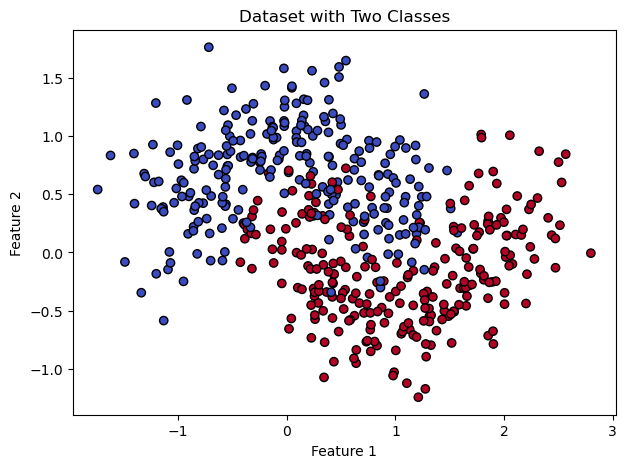

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Dataset with Two Classes")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 350
Testing samples: 150


In [10]:
depths = [1, 2, 3, 5, 10, None]

results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    results.append({
        "Max_Depth": str(depth),
        "Training_Accuracy": train_accuracy,
        "Testing_Accuracy": test_accuracy
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

Max_Depth  Training_Accuracy  Testing_Accuracy
        1           0.831429          0.793333
        2           0.905714          0.880000
        3           0.905714          0.880000
        5           0.948571          0.893333
       10           0.997143          0.866667
     None           1.000000          0.866667


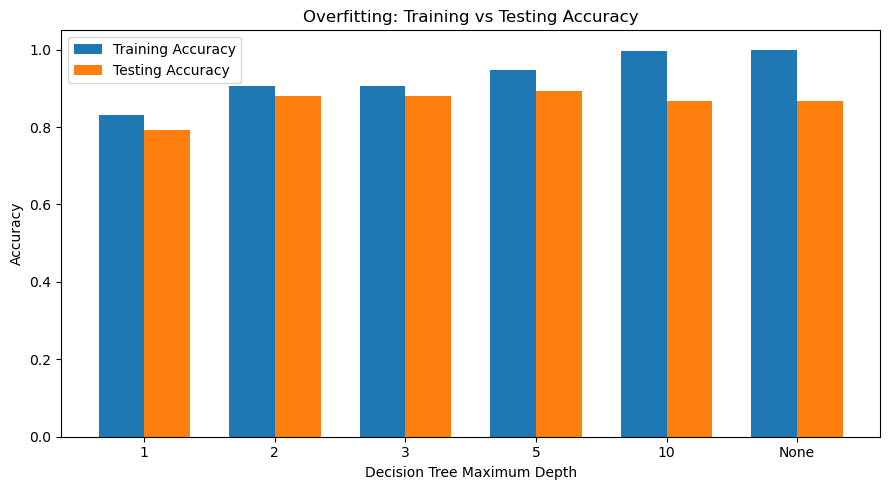

In [11]:
x_positions = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x_positions - width / 2,
    results_df["Training_Accuracy"],
    width,
    label="Training Accuracy"
)

plt.bar(
    x_positions + width / 2,
    results_df["Testing_Accuracy"],
    width,
    label="Testing Accuracy"
)

plt.xticks(x_positions, results_df["Max_Depth"])

plt.xlabel("Decision Tree Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting: Training vs Testing Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

In [12]:
best_index = results_df["Testing_Accuracy"].idxmax()

best_depth = results_df.loc[best_index, "Max_Depth"]
best_accuracy = results_df.loc[best_index, "Testing_Accuracy"]

print("Best tree depth:", best_depth)
print("Best testing accuracy: {:.2f}%".format(best_accuracy * 100))

Best tree depth: 5
Best testing accuracy: 89.33%


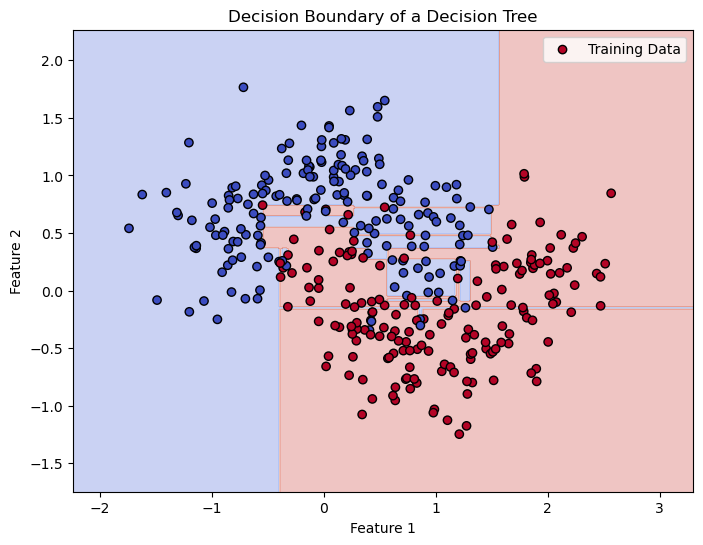

In [13]:
model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid_points)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="black",
    label="Training Data"
)

plt.title("Decision Boundary of a Decision Tree")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [14]:
print("OVERFITTING EXPERIMENT CONCLUSION")
print("---------------------------------")
print("1. Shallow trees may underfit the data.")
print("2. Deep trees can learn complex patterns.")
print("3. Very deep trees may overfit the training data.")
print("4. Training and testing accuracy help identify overfitting.")
print("5. Model complexity should be selected using cross-validation.")

OVERFITTING EXPERIMENT CONCLUSION
---------------------------------
1. Shallow trees may underfit the data.
2. Deep trees can learn complex patterns.
3. Very deep trees may overfit the training data.
4. Training and testing accuracy help identify overfitting.
5. Model complexity should be selected using cross-validation.
